# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Hisyam L Baihaqi
- **Email:** DS297B6Y0737@student.devacademy.id
- **ID Dicoding:** DS297B6Y0737

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

### Pertanyaan Bisnis yang Dijawab

**Konteks:** Operator Capital Bikeshare (Washington D.C.) ingin mengatur ketersediaan armada, jadwal redistribusi, dan perawatan sepeda secara lebih efisien. Dataset yang digunakan mencakup penyewaan harian (`day.csv`) dan per jam (`hour.csv`) sepanjang **2011-2012**.

- **Pertanyaan 1:** *Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur selama 2011-2012, dan berapa selisih penyewaannya pada jam puncak tersebut, sehingga operator dapat menjadwalkan redistribusi sepeda dan perawatan di luar jam sibuk?*
- **Pertanyaan 2:** *Berapa persen rata-rata penyewaan harian turun pada cuaca berkabut dan hujan/salju ringan dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah selama 2011-2012, sehingga operator dapat menyesuaikan jumlah armada aktif dan waktu promosi?*

**Pemeriksaan SMART:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| **Specific** | Jam puncak penyewaan, dibedakan hari kerja vs akhir pekan/libur | Dampak cuaca (3 kategori) dan musim terhadap penyewaan harian |
| **Measurable** | Rata-rata penyewaan per jam & selisihnya di jam puncak | Persentase penurunan vs cuaca cerah & rata-rata harian per musim |
| **Action-Oriented** | Menentukan jam redistribusi sepeda dan jendela perawatan | Menentukan penyesuaian armada dan jadwal promosi |
| **Relevant** | Ketersediaan sepeda di jam sibuk adalah inti kepuasan pengguna | Permintaan yang berfluktuasi karena cuaca/musim memengaruhi biaya operasional |
| **Time-bound** | Data 1 Jan 2011 - 31 Des 2012 | Data 1 Jan 2011 - 31 Des 2012 |

## Import Semua Packages/Library yang Digunakan

In [132]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



## Data Wrangling

### Gathering Data

Dataset **Bike Sharing** (Capital Bikeshare, Washington D.C.) terdiri dari dua file yang berisi informasi yang sama pada granularitas berbeda:
- `day.csv`: agregasi per **hari** (731 baris), dipakai untuk analisis cuaca dan musim (Pertanyaan 2).
- `hour.csv`: agregasi per **jam** (17.379 baris), dipakai untuk analisis pola jam (Pertanyaan 1).

> Jalankan notebook dari folder proyek (yang berisi folder `data/` dan `dashboard/`). Di Google Colab, unggah folder `data/` terlebih dahulu.

#### Load `day.csv`

In [133]:
day_df = pd.read_csv("data/day.csv")
print("Ukuran day_df:", day_df.shape)
day_df.head()

Ukuran day_df: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load `hour.csv`

In [134]:
hour_df = pd.read_csv("data/hour.csv")
print("Ukuran hour_df:", hour_df.shape)
hour_df.head()

Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 hari (1 Jan 2011 - 31 Des 2012) dan `hour_df` berisi 17.379 baris jam, masing-masing dengan variabel kalender, cuaca, serta jumlah penyewa (`casual`, `registered`, `cnt`).
- Kolom `temp`, `atemp`, `hum`, dan `windspeed` masih dalam bentuk **ternormalisasi** (0-1), sehingga perlu dikembalikan ke satuan aslinya agar mudah ditafsirkan.

### Assessing Data

#### Memeriksa missing value, duplikasi, tipe data, dan konsistensi

In [135]:
for nama, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {nama} | shape = {df.shape} ===")
    print("Total missing value          :", df.isna().sum().sum())
    print("Jumlah baris duplikat        :", df.duplicated().sum())
    print("Tipe data kolom dteday       :", df["dteday"].dtype)
    print("Baris casual+registered!=cnt :", ((df["casual"] + df["registered"]) != df["cnt"]).sum())
    print()

=== day_df | shape = (731, 16) ===
Total missing value          : 0
Jumlah baris duplikat        : 0
Tipe data kolom dteday       : str
Baris casual+registered!=cnt : 0

=== hour_df | shape = (17379, 17) ===
Total missing value          : 0
Jumlah baris duplikat        : 0
Tipe data kolom dteday       : str
Baris casual+registered!=cnt : 0



In [136]:
day_df[["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]].describe().round(3)

,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000,731.000,731.000,731.000,731.000,731.000,731.000
mean,0.495,0.474,0.628,0.190,848.176,3656.172,4504.349
std,0.183,0.163,0.142,0.077,686.622,1560.256,1937.211
min,0.059,0.079,0.000,0.022,2.000,20.000,22.000
25%,0.337,0.338,0.520,0.135,315.500,2497.000,3152.000
50%,0.498,0.487,0.627,0.181,713.000,3662.000,4548.000
75%,0.655,0.609,0.730,0.233,1096.000,4776.500,5956.000
max,0.862,0.841,0.972,0.507,3410.000,6946.000,8714.000


**Insight:**
- Tidak ada missing value maupun duplikat, dan `casual + registered = cnt` konsisten di semua baris.
- Kolom `dteday` bertipe string (bukan tanggal) sehingga tidak bisa dipakai untuk analisis berbasis waktu.
- Pada ringkasan statistik, `hum` memiliki nilai minimum **0**, yang janggal untuk kelembapan udara.

#### Identifying invalid value (kelembapan) dan inaccurate value (windspeed)

In [137]:
print("Jumlah hum == 0 di day_df  :", (day_df["hum"] == 0).sum())
print("Jumlah hum == 0 di hour_df :", (hour_df["hum"] == 0).sum())
print("Tanggal terkait di hour_df :", list(hour_df.loc[hour_df["hum"] == 0, "dteday"].unique()))
print("Jumlah windspeed == 0 di hour_df:", (hour_df["windspeed"] == 0).sum(),
      f"({(hour_df['windspeed'] == 0).mean():.1%} dari seluruh baris)")
day_df.loc[day_df["hum"] == 0, ["dteday", "temp", "hum", "weathersit", "cnt"]]

Jumlah hum == 0 di day_df  : 1
Jumlah hum == 0 di hour_df : 22
Tanggal terkait di hour_df : ['2011-03-10']
Jumlah windspeed == 0 di hour_df: 2180 (12.5% dari seluruh baris)


,dteday,temp,hum,weathersit,cnt
68,2011-03-10,0.389091,0.0,3,623


**Insight:**
- Terdapat 1 hari (**2011-03-10**) dengan `hum = 0`; pada `hour_df` ini berdampak pada 22 baris jam di tanggal yang sama. Kelembapan 0% tidak masuk akal pada hari berstatus hujan/salju ringan, sehingga ini adalah **invalid value** (kemungkinan sensor tidak mencatat).
- `windspeed = 0` muncul pada 2.180 baris jam (12,5%). Ini kemungkinan keterbatasan presisi/pencatatan sensor, bukan angin yang benar-benar nol. Kolom ini **tidak dipakai** untuk menjawab pertanyaan bisnis, sehingga dibiarkan namun dicatat sebagai keterbatasan.

#### Identifying inaccurate value (label musim)

In [138]:
# Validasi label musim: Readme menyebut 1=Spring, 2=Summer, 3=Fall, 4=Winter. Benarkah?
print("Jumlah hari per kode musim x bulan:")
print(pd.crosstab(day_df["season"], day_df["mnth"]))
print("\nRata-rata suhu (°C) per kode musim:")
(day_df.groupby("season")["temp"].mean() * 41).round(1)

Jumlah hari per kode musim x bulan:
mnth    1   2   3   4   5   6   7   8   9   10  11  12
season                                                
1       62  57  40   0   0   0   0   0   0   0   0  22
2        0   0  22  60  62  40   0   0   0   0   0   0
3        0   0   0   0   0  20  62  62  44   0   0   0
4        0   0   0   0   0   0   0   0  16  62  60  40

Rata-rata suhu (°C) per kode musim:


season
1    12.2
2    22.3
3    29.0
4    17.3
Name: temp, dtype: float64

**Insight:**
- Readme.txt menyebut `season` 1 = Spring, 2 = Summer, 3 = Fall, 4 = Winter. Namun data menunjukkan kode **1** mencakup Januari-Maret dan Desember (suhu rata-rata hanya 12,2°C), sedangkan kode **3** mencakup Juni-September (suhu 29,0°C).
- Artinya kode musim mengikuti batas astronomis: **1 = Musim Dingin, 2 = Musim Semi, 3 = Musim Panas, 4 = Musim Gugur**. Label pada Readme **tidak akurat** dan jika dipakai apa adanya akan menghasilkan kesimpulan musiman yang terbalik.

#### Identifying missing data per jam

In [139]:
jam_diharapkan = len(day_df) * 24
jam_tersedia = len(hour_df)
jam_per_hari = hour_df.groupby("dteday").size()

print("Jam yang seharusnya ada (731 hari x 24):", jam_diharapkan)
print("Jam yang tersedia di hour.csv           :", jam_tersedia)
print("Jam yang hilang                         :", jam_diharapkan - jam_tersedia)
print("Jumlah hari dengan data jam tidak lengkap:", (jam_per_hari < 24).sum())
print()
print("Hari dengan jam paling sedikit:")
jam_per_hari.sort_values().head(3)

Jam yang seharusnya ada (731 hari x 24): 17544
Jam yang tersedia di hour.csv           : 17379
Jam yang hilang                         : 165
Jumlah hari dengan data jam tidak lengkap: 76

Hari dengan jam paling sedikit:


dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
dtype: int64

**Insight:**
- `hour.csv` hanya memiliki 17.379 baris dari seharusnya 17.544 (731 hari x 24 jam), jadi **165 jam hilang** pada 76 hari.
- Hari dengan jam paling sedikit adalah **2012-10-29 (hanya 1 jam)**, bertepatan dengan Badai Sandy. Jam yang hilang kemungkinan besar adalah jam tanpa transaksi (bukan error), terutama dini hari. Jika dibiarkan, rata-rata per jam akan **terlalu tinggi** karena jam sepi tidak ikut dihitung.

#### Identifying outlier

In [140]:
# 1) Metode IQR pada total penyewaan harian
q1, q3 = day_df["cnt"].quantile([0.25, 0.75])
iqr = q3 - q1
batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Batas IQR: {batas_bawah:.0f} s.d. {batas_atas:.0f}")
print("Hari di luar batas IQR:", (~day_df["cnt"].between(batas_bawah, batas_atas)).sum())

# 2) Karena data bersifat musiman, bandingkan juga dengan median bulan yang sama
median_bulanan = day_df.groupby(["yr", "mnth"])["cnt"].transform("median")
day_df["rasio_median_bulan"] = day_df["cnt"] / median_bulanan
print("\nHari dengan penyewaan < 25% dari median bulannya:")
day_df.loc[day_df["rasio_median_bulan"] < 0.25, ["dteday", "weathersit", "cnt", "rasio_median_bulan"]]

Batas IQR: -1054 s.d. 10162
Hari di luar batas IQR: 0

Hari dengan penyewaan < 25% dari median bulannya:


,dteday,weathersit,cnt,rasio_median_bulan
105,2011-04-16,3,795,0.246397
238,2011-08-27,2,1115,0.242286
301,2011-10-29,3,627,0.145678
340,2011-12-07,3,705,0.229791
358,2011-12-25,1,754,0.245763
477,2012-04-22,3,1027,0.165259
667,2012-10-29,3,22,0.003021
668,2012-10-30,2,1096,0.150508
723,2012-12-24,2,920,0.197892
724,2012-12-25,2,1013,0.217896


**Insight:**
- Metode IQR murni tidak menemukan outlier karena distribusi harian sangat lebar akibat musiman (batas bawah negatif), sehingga kurang informatif.
- Dengan membandingkan terhadap median bulan yang sama, terlihat 11 hari berpenyewaan sangat rendah. Yang paling ekstrem adalah **2012-10-29 (22 penyewaan)** saat Badai Sandy, lalu 2012-10-30 dan 2012-12-26. Ini adalah peristiwa nyata, bukan kesalahan data.

**Steps to Take (rencana Cleaning Data):**
1. Mengubah `dteday` menjadi tipe `datetime`.
2. Mengubah kode numerik (musim, cuaca, hari, bulan, tahun) menjadi label, dengan **pemetaan musim yang dikoreksi**, serta membuat kolom `day_type` (Hari Kerja vs Akhir Pekan/Libur).
3. Mengembalikan `temp`, `atemp`, `hum`, `windspeed` ke satuan aslinya (°C, %, km/jam).
4. Mengganti `hum = 0` (invalid) dengan interpolasi dari nilai di sekitarnya.
5. Melengkapi 165 jam yang hilang pada data per jam dengan `cnt = 0`.
6. Mempertahankan hari anomali (peristiwa nyata) namun memberi penanda `anomali`.

### Cleaning Data

#### 1. Memperbaiki tipe data tanggal

In [141]:
# 1) Ubah tipe data tanggal dari string menjadi datetime
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

print(day_df["dteday"].dtype, "|", hour_df["dteday"].dtype)
print("Rentang tanggal:", day_df["dteday"].min().date(), "s.d.", day_df["dteday"].max().date())

datetime64[us] | datetime64[us]
Rentang tanggal: 2011-01-01 s.d. 2012-12-31


#### 2. Membuat label kategori (termasuk koreksi label musim)

In [142]:
# 2) Ubah kode numerik menjadi label yang mudah dibaca
# Catatan: label musim pada Readme.txt tidak sesuai kalender (lihat tahap Assessing).
# Pemetaan di bawah ini sudah dikoreksi berdasarkan bulan & suhu aktual.
MAP_MUSIM = {1: "Musim Dingin", 2: "Musim Semi", 3: "Musim Panas", 4: "Musim Gugur"}
MAP_CUACA = {1: "Cerah", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
MAP_HARI = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
MAP_BULAN = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

def tambah_label(df):
    df["season_label"] = df["season"].map(MAP_MUSIM)
    df["weathersit_label"] = df["weathersit"].map(MAP_CUACA)
    df["weekday_name"] = df["weekday"].map(MAP_HARI)
    df["month_name"] = df["mnth"].map(MAP_BULAN)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    return df

day_df = tambah_label(day_df)
hour_df = tambah_label(hour_df)
day_df[["dteday", "season_label", "weathersit_label", "weekday_name", "year", "day_type"]].head()

,dteday,season_label,weathersit_label,weekday_name,year,day_type
0,2011-01-01,Musim Dingin,Berkabut/Mendung,Sabtu,2011,Akhir Pekan/Libur
1,2011-01-02,Musim Dingin,Berkabut/Mendung,Minggu,2011,Akhir Pekan/Libur
2,2011-01-03,Musim Dingin,Cerah,Senin,2011,Hari Kerja
3,2011-01-04,Musim Dingin,Cerah,Selasa,2011,Hari Kerja
4,2011-01-05,Musim Dingin,Cerah,Rabu,2011,Hari Kerja


#### 3. Mengembalikan nilai ternormalisasi ke satuan asli

In [143]:
# 3) Kembalikan nilai cuaca yang ternormalisasi ke satuan aslinya (sesuai Readme.txt)
for df in (day_df, hour_df):
    df["temp_c"] = df["temp"] * 41          # suhu (°C)
    df["atemp_c"] = df["atemp"] * 50        # suhu yang dirasakan (°C)
    df["hum_pct"] = df["hum"] * 100         # kelembapan (%)
    df["windspeed_kmh"] = df["windspeed"] * 67  # kecepatan angin

day_df[["temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].describe().round(2)

,temp_c,atemp_c,hum_pct,windspeed_kmh
count,731.00,731.00,731.00,731.00
mean,20.31,23.72,62.79,12.76
std,7.51,8.15,14.24,5.19
min,2.42,3.95,0.00,1.50
25%,13.82,16.89,52.00,9.04
50%,20.43,24.34,62.67,12.13
75%,26.87,30.43,73.02,15.63
max,35.33,42.04,97.25,34.00


#### 4. Memperbaiki invalid value (kelembapan = 0)

In [144]:
# 4) Perbaiki nilai invalid: kelembapan 0% dianggap tidak terukur -> interpolasi dari hari/jam di sekitarnya
day_df = day_df.sort_values("dteday").reset_index(drop=True)
hour_df = hour_df.sort_values(["dteday", "hr"]).reset_index(drop=True)

for df in (day_df, hour_df):
    df.loc[df["hum_pct"] == 0, "hum_pct"] = np.nan
    df["hum_pct"] = df["hum_pct"].interpolate(limit_direction="both")

print("hum_pct == 0 tersisa (day, hour):", (day_df["hum_pct"] == 0).sum(), (hour_df["hum_pct"] == 0).sum())
print("Kelembapan 2011-03-10 setelah diperbaiki:", day_df.loc[day_df["dteday"] == "2011-03-10", "hum_pct"].round(1).iloc[0], "%")

hum_pct == 0 tersisa (day, hour): 0 0
Kelembapan 2011-03-10 setelah diperbaiki: 71.2 %


#### 5. Melengkapi jam yang hilang

In [145]:
# 5) Lengkapi jam yang hilang: tidak ada baris = tidak ada penyewaan, sehingga cnt diisi 0.
#    Tanpa langkah ini rata-rata per jam akan terlalu tinggi, terutama pada jam sepi (dini hari).
hour_df["datetime"] = hour_df["dteday"] + pd.to_timedelta(hour_df["hr"], unit="h")
semua_jam = pd.date_range(day_df["dteday"].min(), day_df["dteday"].max() + pd.Timedelta(hours=23), freq="h")

hour_full = hour_df.set_index("datetime").reindex(semua_jam)
hour_full.index.name = "datetime"
hour_full["jam_dilengkapi"] = hour_full["cnt"].isna()

for kolom in ["casual", "registered", "cnt"]:
    hour_full[kolom] = hour_full[kolom].fillna(0).astype(int)

# Atribut tanggal diambil dari day_df, variabel cuaca diinterpolasi
hour_full["dteday"] = hour_full.index.normalize()
hour_full["hr"] = hour_full.index.hour
kolom_tanggal = ["season", "yr", "mnth", "weekday", "workingday", "holiday", "season_label",
                 "weekday_name", "month_name", "year", "day_type"]
hour_full[kolom_tanggal] = day_df.set_index("dteday")[kolom_tanggal].reindex(hour_full["dteday"]).values
for kolom in ["season", "yr", "mnth", "weekday", "workingday", "holiday", "year"]:
    hour_full[kolom] = hour_full[kolom].astype(int)

hour_full[["temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]] = (
    hour_full[["temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].interpolate(method="time"))
hour_full["weathersit"] = hour_full["weathersit"].ffill().astype(int)
hour_full["weathersit_label"] = hour_full["weathersit"].map(MAP_CUACA)

hour_full = hour_full.drop(columns=["instant", "temp", "atemp", "hum", "windspeed"]).reset_index()

print("Jumlah baris hour_full         :", len(hour_full))
print("Jam yang dilengkapi (cnt = 0)  :", hour_full["jam_dilengkapi"].sum())
print("Total cnt sebelum vs sesudah   :", hour_df["cnt"].sum(), "vs", hour_full["cnt"].sum())
print("Sisa missing value             :", hour_full.isna().sum().sum())

Jumlah baris hour_full         : 17544
Jam yang dilengkapi (cnt = 0)  : 165
Total cnt sebelum vs sesudah   : 3292679 vs 3292679
Sisa missing value             : 0


#### 6. Menandai hari anomali

In [146]:
# 6) Penyewaan ekstrem rendah: dipertahankan (peristiwa nyata), hanya diberi penanda
day_df["anomali"] = day_df["rasio_median_bulan"] < 0.25
print("Jumlah hari ditandai anomali:", day_df["anomali"].sum())
day_df.loc[day_df["anomali"], ["dteday", "weathersit_label", "cnt"]]

Jumlah hari ditandai anomali: 11


,dteday,weathersit_label,cnt
105,2011-04-16,Hujan/Salju Ringan,795
238,2011-08-27,Berkabut/Mendung,1115
301,2011-10-29,Hujan/Salju Ringan,627
340,2011-12-07,Hujan/Salju Ringan,705
358,2011-12-25,Cerah,754
477,2012-04-22,Hujan/Salju Ringan,1027
667,2012-10-29,Hujan/Salju Ringan,22
668,2012-10-30,Berkabut/Mendung,1096
723,2012-12-24,Berkabut/Mendung,920
724,2012-12-25,Berkabut/Mendung,1013


#### Menggabungkan dan menyimpan data bersih untuk dashboard

In [147]:
# Gabungkan data harian ke data per jam menjadi SATU file untuk dashboard.
# Granularitas file gabungan = per jam (hour_full). Kolom milik data harian diberi akhiran "_harian"
# agar tidak tertukar dengan nilai per jam (misalnya cnt per jam vs cnt per hari).
kolom_harian = ["casual", "registered", "cnt", "weathersit_label", "temp_c", "hum_pct", "windspeed_kmh", "anomali"]
day_untuk_gabung = day_df[["dteday"] + kolom_harian].rename(columns={k: f"{k}_harian" for k in kolom_harian})

main_df = hour_full.merge(day_untuk_gabung, on="dteday", how="left", validate="many_to_one")
assert main_df[[f"{k}_harian" for k in kolom_harian]].isna().sum().sum() == 0, "Ada jam yang tidak punya pasangan data harian"
assert len(main_df) == len(hour_full)

# Simpan data bersih untuk dashboard
os.makedirs("dashboard", exist_ok=True)
main_df.to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan: dashboard/main_data.csv", main_df.shape)

Tersimpan: dashboard/main_data.csv (17544, 32)


**Insight:**
- Kelembapan 2011-03-10 kini bernilai wajar (71,2%) dan semua variabel cuaca sudah dalam satuan asli.
- Data per jam kini lengkap 17.544 baris tanpa mengubah total penyewaan (3.292.679), karena jam yang dilengkapi bernilai 0.
- Label musim sudah dikoreksi sehingga sesuai dengan kalender dan suhu aktual.

## Exploratory Data Analysis (EDA)

### Gambaran Umum Data

In [148]:
day_df[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed_kmh"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,windspeed_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


In [149]:
ringkas_tahun = day_df.groupby("year").agg(
    total_penyewaan=("cnt", "sum"),
    rata_rata_harian=("cnt", "mean"),
    total_registered=("registered", "sum"),
).round(1)
ringkas_tahun["pct_registered"] = (ringkas_tahun["total_registered"] / ringkas_tahun["total_penyewaan"] * 100).round(1)
pertumbuhan = (ringkas_tahun.loc[2012, "total_penyewaan"] / ringkas_tahun.loc[2011, "total_penyewaan"] - 1) * 100
print(f"Pertumbuhan total penyewaan 2012 vs 2011: {pertumbuhan:.1f}%")
ringkas_tahun

Pertumbuhan total penyewaan 2012 vs 2011: 64.9%


,total_penyewaan,rata_rata_harian,total_registered,pct_registered
year,,,,
2011,1243103,3405.8,995851,80.1
2012,2049576,5599.9,1676811,81.8


In [150]:
day_df[["cnt", "temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].corr()["cnt"].drop("cnt").round(2).sort_values(ascending=False)

temp_c           0.63
atemp_c          0.63
hum_pct         -0.12
windspeed_kmh   -0.23
Name: cnt, dtype: float64

**Insight:**
- Rata-rata penyewaan harian sekitar 4.504 sepeda dengan rentang yang sangat lebar (22 s.d. 8.714), tanda kuat adanya pengaruh faktor musiman/cuaca.
- Total penyewaan **tumbuh 64,9%** dari 2011 ke 2012 (1,24 juta menjadi 2,05 juta). Pertumbuhan ini perlu diperhatikan agar perbandingan antar kondisi tidak bias oleh tahun.
- Sekitar 80% penyewa adalah pengguna **registered**.
- Suhu berkorelasi positif sedang dengan penyewaan (r = 0,63), sedangkan kecepatan angin (r = -0,23) dan kelembapan (r = -0,12) berkorelasi negatif lemah.

### Explore Pertanyaan 1: Pola Penyewaan per Jam (Hari Kerja vs Akhir Pekan/Libur)

In [151]:
# Rata-rata penyewaan per jam, dihitung dari seluruh jam (termasuk jam yang dilengkapi = 0)
pola_jam = hour_full.pivot_table(index="hr", columns="day_type", values="cnt", aggfunc="mean").round(1)
pola_jam

day_type,Akhir Pekan/Libur,Hari Kerja
hr,,
0,90.4,36.5
1,69.2,16.4
2,52.5,8.5
3,25.3,4.6
4,8.1,5.1
5,8.4,24.7
6,18.6,101.7
7,43.4,288.3
8,105.7,473.2


In [152]:
ringkas_q1 = pd.DataFrame({
    "jam_puncak": pola_jam.idxmax(),
    "rata_rata_di_puncak": pola_jam.max(),
    "rata_rata_seluruh_jam": pola_jam.mean().round(1),
    "total_rata_rata_per_hari": (pola_jam.sum()).round(0),
})
print("Tiga jam tertinggi per tipe hari:")
for tipe in pola_jam.columns:
    print(f"  {tipe}:", [f"{j:02d}.00 ({v:.0f})" for j, v in pola_jam[tipe].nlargest(3).items()])
print()
ringkas_q1

Tiga jam tertinggi per tipe hari:
  Akhir Pekan/Libur: ['13.00 (373)', '12.00 (366)', '14.00 (365)']
  Hari Kerja: ['17.00 (524)', '18.00 (490)', '08.00 (473)']



,jam_puncak,rata_rata_di_puncak,rata_rata_seluruh_jam,total_rata_rata_per_hari
day_type,,,,
Akhir Pekan/Libur,13,372.7,180.4,4330.0
Hari Kerja,17,524.2,191.0,4585.0


In [153]:
# Komposisi pengguna pada jam puncak
for tipe in ["Hari Kerja", "Akhir Pekan/Libur"]:
    sub = hour_full[hour_full["day_type"] == tipe].groupby("hr")[["casual", "registered", "cnt"]].mean()
    jam = sub["cnt"].idxmax()
    print(f"{tipe}: pukul {jam:02d}.00 -> registered {sub.loc[jam, 'registered'] / sub.loc[jam, 'cnt']:.0%}, "
          f"casual {sub.loc[jam, 'casual'] / sub.loc[jam, 'cnt']:.0%}")

Hari Kerja: pukul 17.00 -> registered 89%, casual 11%
Akhir Pekan/Libur: pukul 13.00 -> registered 63%, casual 37%


**Insight:**
- **Hari kerja** memiliki dua puncak komuter: **08.00 (473/jam)** dan puncak tertinggi **17.00 (524/jam)**, diikuti 18.00 (490/jam).
- **Akhir pekan/libur** hanya memiliki satu puncak landai di siang hari, tertinggi **13.00 (373/jam)** dan relatif datar pada 11.00-15.00.
- Pada jam 17.00, penyewaan hari kerja (524) lebih tinggi sekitar 62% daripada akhir pekan (324). Pada jam 08.00 selisihnya jauh lebih besar: 473 vs 106 (sekitar 4,5x).
- Total penyewaan per hari justru mirip (4.585 hari kerja vs 4.330 akhir pekan), jadi bedanya ada pada **waktu**, bukan volume.
- Puncak hari kerja didominasi pengguna terdaftar (89%), sedangkan puncak akhir pekan memiliki porsi pengguna kasual yang jauh lebih besar (37%).
- Hari kerja paling sepi pada 02.00-04.00 (hanya 4-9 penyewaan/jam).

### Explore Pertanyaan 2: Pengaruh Cuaca dan Musim terhadap Penyewaan Harian

In [154]:
urutan_cuaca = ["Cerah", "Berkabut/Mendung", "Hujan/Salju Ringan"]
cuaca = day_df.groupby("weathersit_label").agg(
    jumlah_hari=("cnt", "size"),
    rata_rata_cnt=("cnt", "mean"),
    median_cnt=("cnt", "median"),
).reindex(urutan_cuaca).round(0)
cuaca["selisih_vs_cerah_%"] = ((cuaca["rata_rata_cnt"] / cuaca.loc["Cerah", "rata_rata_cnt"] - 1) * 100).round(1)
cuaca

,jumlah_hari,rata_rata_cnt,median_cnt,selisih_vs_cerah_%
weathersit_label,,,,
Cerah,463,4877.0,4844.0,0.0
Berkabut/Mendung,247,4036.0,4040.0,-17.2
Hujan/Salju Ringan,21,1803.0,1817.0,-63.0


In [155]:
urutan_musim = ["Musim Dingin", "Musim Semi", "Musim Panas", "Musim Gugur"]
musim = day_df.groupby("season_label").agg(
    jumlah_hari=("cnt", "size"),
    rata_rata_cnt=("cnt", "mean"),
    median_cnt=("cnt", "median"),
    rata_rata_suhu_c=("temp_c", "mean"),
).reindex(urutan_musim).round(1)
musim

,jumlah_hari,rata_rata_cnt,median_cnt,rata_rata_suhu_c
season_label,,,,
Musim Dingin,181,2604.1,2209.0,12.2
Musim Semi,184,4992.3,4941.5,22.3
Musim Panas,188,5644.3,5353.5,29.0
Musim Gugur,178,4728.2,4634.5,17.3


In [156]:
# Uji ketahanan: apakah pola cuaca tetap sama di tiap tahun & musim? (menghindari bias pertumbuhan 2012)
print("Rata-rata penyewaan harian: cuaca x tahun")
print(day_df.pivot_table(index="weathersit_label", columns="year", values="cnt", aggfunc="mean").reindex(urutan_cuaca).round(0))
print("\nRata-rata penyewaan harian: cuaca x musim")
print(day_df.pivot_table(index="weathersit_label", columns="season_label", values="cnt", aggfunc="mean").reindex(urutan_cuaca)[urutan_musim].round(0))
print("\nJumlah hari: cuaca x musim")
day_df.pivot_table(index="weathersit_label", columns="season_label", values="cnt", aggfunc="size").reindex(urutan_cuaca)[urutan_musim]

Rata-rata penyewaan harian: cuaca x tahun
year                  2011    2012
weathersit_label                  
Cerah               3695.0  6004.0
Berkabut/Mendung    3088.0  4991.0
Hujan/Salju Ringan  1674.0  2126.0

Rata-rata penyewaan harian: cuaca x musim
season_label        Musim Dingin  Musim Semi  Musim Panas  Musim Gugur
weathersit_label                                                      
Cerah                     2811.0      5549.0       5878.0       5044.0
Berkabut/Mendung          2357.0      4237.0       5222.0       4654.0
Hujan/Salju Ringan         935.0      1169.0       2752.0       1962.0

Jumlah hari: cuaca x musim


season_label,Musim Dingin,Musim Semi,Musim Panas,Musim Gugur
weathersit_label,,,,
Cerah,111,113,136,103
Berkabut/Mendung,66,68,48,65
Hujan/Salju Ringan,4,3,4,10


**Insight:**
- Dibandingkan hari cerah (rata-rata 4.877/hari), hari **berkabut/mendung turun 17,2%** (4.036) dan hari **hujan/salju ringan turun 63,0%** (1.803).
- Musim dengan rata-rata tertinggi adalah **Musim Panas (5.644/hari)** dan terendah **Musim Dingin (2.604/hari)**, yaitu sekitar 54% lebih rendah.
- Pola cuaca konsisten: urutan Cerah > Berkabut > Hujan/Salju Ringan terjadi di **kedua tahun** dan di **keempat musim**, sehingga temuan tidak semata-mata akibat pertumbuhan 2012 atau komposisi musim.
- **Catatan keterbatasan:** hari hujan/salju ringan hanya 21 hari (3-10 hari per musim) dan tidak ada hari bercuaca lebat pada `day.csv`, sehingga angka -63% perlu dibaca sebagai indikasi kuat, bukan estimasi presisi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa penyewaan mencapai puncak pada hari kerja vs akhir pekan/libur, dan berapa selisihnya?

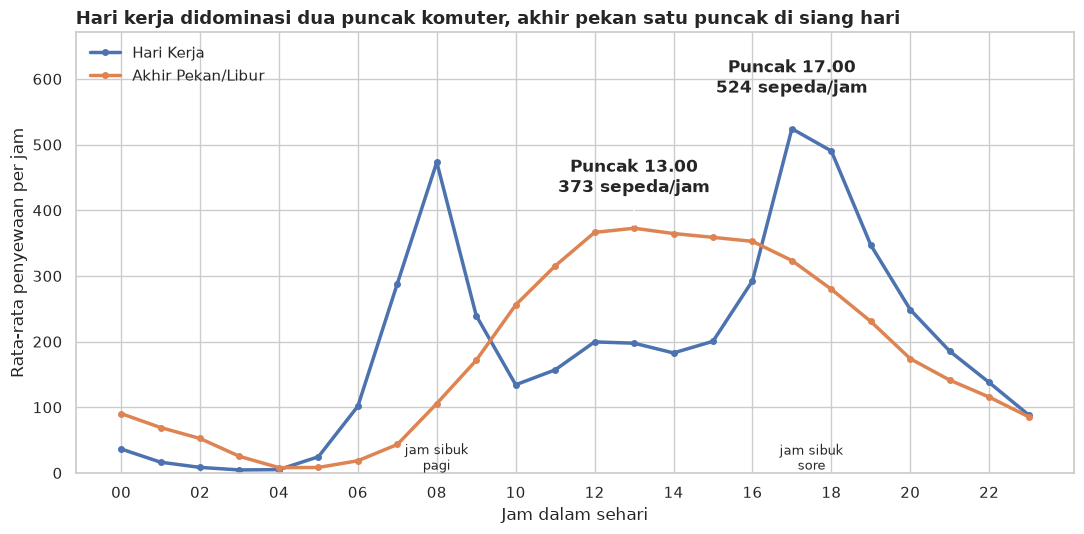

In [157]:
fig, ax = plt.subplots(figsize=(11, 5.5))

for tipe in ["Hari Kerja", "Akhir Pekan/Libur"]:
    ax.plot(pola_jam.index, pola_jam[tipe], marker="o", ms=4, lw=2.5, label=tipe)
    jam_p, nilai_p = pola_jam[tipe].idxmax(), pola_jam[tipe].max()
    ax.annotate(f"Puncak {jam_p:02d}.00\n{nilai_p:.0f} sepeda/jam", xy=(jam_p, nilai_p),
                xytext=(jam_p, nilai_p + 55), ha="center", fontweight="bold",
                arrowprops=dict(arrowstyle="-"))

ax.text(8, 5, "jam sibuk\npagi", ha="center", fontsize=9)
ax.text(17.5, 5, "jam sibuk\nsore", ha="center", fontsize=9)
ax.set_ylim(0, pola_jam.max().max() * 1.28)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{j:02d}" for j in range(0, 24, 2)])
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_title("Hari kerja didominasi dua puncak komuter, akhir pekan satu puncak di siang hari",
             loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** satu garis untuk hari kerja dan satu garis untuk akhir pekan/libur (lihat legenda). Judul grafik menyatakan temuan utama, sumbu Y dimulai dari nol agar perbandingan tidak menyesatkan, dan hanya dua puncak utama yang diberi anotasi.

### Pertanyaan 2: Seberapa besar cuaca menurunkan penyewaan, dan musim apa tertinggi/terendah?

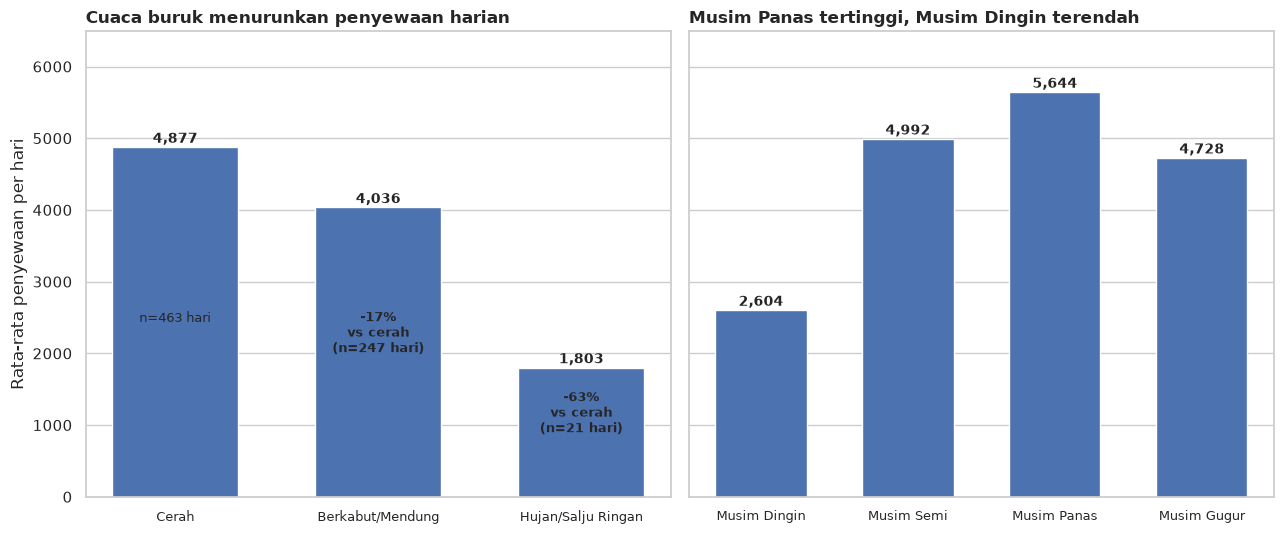

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

def bar_sorot(ax, data, judul):
    batang = ax.bar(data.index, data["rata_rata_cnt"], width=0.62)
    for b, (_, baris) in zip(batang, data.iterrows()):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 60, f"{baris['rata_rata_cnt']:,.0f}",
                ha="center", fontweight="bold", fontsize=10)
    ax.set_title(judul, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(False, axis="x")

# Panel kiri: cuaca (tampilkan selisih vs cerah)
bar_sorot(axes[0], cuaca, "Cuaca buruk menurunkan penyewaan harian")
for i, (nama, baris) in enumerate(cuaca.iterrows()):
    if nama != "Cerah":
        axes[0].text(i, baris["rata_rata_cnt"] / 2, f"{baris['selisih_vs_cerah_%']:.0f}%\nvs cerah\n(n={int(baris['jumlah_hari'])} hari)",
                     ha="center", fontweight="bold", fontsize=9)
    else:
        axes[0].text(i, baris["rata_rata_cnt"] / 2, f"n={int(baris['jumlah_hari'])} hari", ha="center", fontsize=9)

# Panel kanan: musim
tertinggi, terendah = musim["rata_rata_cnt"].idxmax(), musim["rata_rata_cnt"].idxmin()
bar_sorot(axes[1], musim, f"{tertinggi} tertinggi, {terendah} terendah")

axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_ylim(0, musim["rata_rata_cnt"].max() * 1.15)
plt.tight_layout()
plt.show()

**Cara membaca:** kedua panel memakai skala sumbu Y yang sama sehingga tinggi batang dapat dibandingkan langsung. Jumlah hari (n) ditampilkan agar pembaca tahu seberapa kuat dasar angkanya, terutama pada kategori hujan/salju ringan (n = 21).

**Insight:**
- Pada hari kerja, penyewaan melonjak di dua jam sibuk (sekitar 07.00-09.00 dan 16.00-19.00), sedangkan akhir pekan berpusat di siang hari. Jam puncak: **17.00 untuk hari kerja** dan **13.00 untuk akhir pekan/libur**.
- Penyewaan turun 17,2% saat berkabut/mendung dan 63,0% saat hujan/salju ringan; **Musim Panas** tertinggi, **Musim Dingin** terendah.

## Analisis Lanjutan (Opsional)

Teknik yang digunakan adalah **Manual Grouping** dan **Binning** (tanpa algoritma machine learning). Teknik ini dipilih karena dataset berupa deret waktu agregat tanpa data pelanggan individual (tidak ada ID pelanggan atau transaksi sehingga RFM tidak relevan) dan tanpa koordinat lokasi (sehingga analisis geospasial tidak relevan).

1. **Manual Grouping** jam menjadi segmen waktu (Dini Hari, Pagi, Siang, Sore, Malam) berdasarkan pola penggunaan.
2. **Binning** suhu harian dengan `pd.cut` menjadi 4 kelompok.
3. **Manual Grouping** (kuantil) permintaan harian menjadi Rendah/Sedang/Tinggi dengan `pd.qcut`.
4. **Peta panas** hari x jam untuk melihat pola jam sibuk secara menyeluruh.

In [159]:
# Manual grouping: membagi 24 jam menjadi segmen waktu berdasarkan pola penggunaan
batas_jam = [-1, 5, 9, 15, 19, 23]
label_segmen = ["Dini Hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"]
hour_full["segmen_waktu"] = pd.cut(hour_full["hr"], bins=batas_jam, labels=label_segmen)

segmen = hour_full.pivot_table(index="segmen_waktu", columns="day_type", values="cnt", aggfunc="sum", observed=True)
segmen = segmen[["Hari Kerja", "Akhir Pekan/Libur"]]  # urutan & warna konsisten dengan grafik sebelumnya
segmen_pct = (segmen / segmen.sum() * 100).round(1)
segmen_pct

day_type,Hari Kerja,Akhir Pekan/Libur
segmen_waktu,,
Dini Hari (00-05),2.1,5.9
Pagi (06-09),24.1,7.8
Siang (10-15),23.4,47.0
Sore (16-19),36.1,27.4
Malam (20-23),14.4,11.9


In [160]:
# Binning: kelompokkan suhu harian (°C) menggunakan pd.cut
day_df["kategori_suhu"] = pd.cut(day_df["temp_c"], bins=[0, 10, 20, 30, 50], right=False,
                                 labels=["< 10°C", "10-20°C", "20-30°C", ">= 30°C"])
suhu = day_df.groupby("kategori_suhu", observed=True).agg(
    jumlah_hari=("cnt", "size"), rata_rata_cnt=("cnt", "mean")).round(0)
suhu

,jumlah_hari,rata_rata_cnt
kategori_suhu,,
< 10°C,60,1678.0
10-20°C,299,3692.0
20-30°C,300,5662.0
>= 30°C,72,5410.0


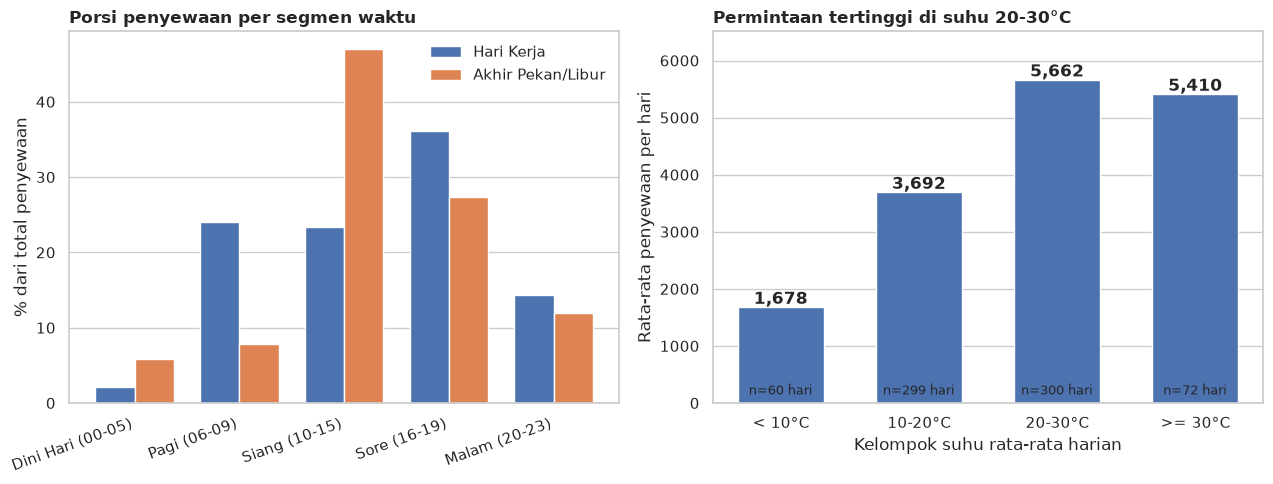

In [161]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel kiri: porsi penyewaan per segmen waktu
segmen_pct.plot(kind="bar", ax=axes[0], width=0.75)
axes[0].set_title("Porsi penyewaan per segmen waktu", loc="left", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("% dari total penyewaan")
axes[0].set_xticklabels(segmen_pct.index, rotation=20, ha="right")
axes[0].legend(title="", frameon=False)

# Panel kanan: rata-rata penyewaan per kelompok suhu
batang = axes[1].bar(suhu.index.astype(str), suhu["rata_rata_cnt"], width=0.62)
for b, (_, baris) in zip(batang, suhu.iterrows()):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 60, f"{baris['rata_rata_cnt']:,.0f}",
                 ha="center", fontweight="bold")
    axes[1].text(b.get_x() + b.get_width() / 2, 150, f"n={int(baris['jumlah_hari'])} hari",
                 ha="center", fontsize=9)
axes[1].set_title(f"Permintaan tertinggi di suhu {suhu['rata_rata_cnt'].idxmax()}", loc="left", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kelompok suhu rata-rata harian")
axes[1].set_ylabel("Rata-rata penyewaan per hari")
axes[1].set_ylim(0, suhu["rata_rata_cnt"].max() * 1.15)
axes[0].grid(False, axis="x")
axes[1].grid(False, axis="x")
plt.tight_layout()
plt.show()

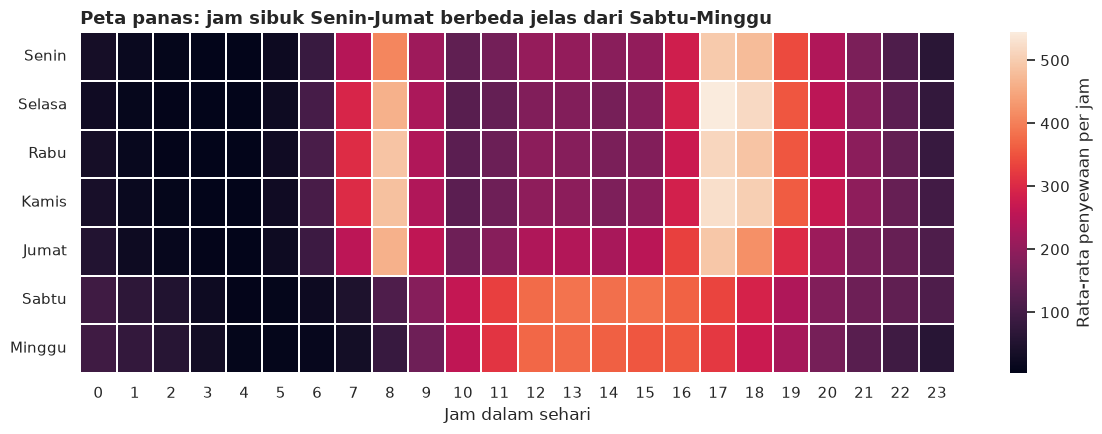

In [162]:
urutan_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
heat = hour_full.pivot_table(index="weekday_name", columns="hr", values="cnt", aggfunc="mean").reindex(urutan_hari)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(heat, ax=ax, cbar_kws={"label": "Rata-rata penyewaan per jam"}, linewidths=0.3, linecolor="white")
ax.set_title("Peta panas: jam sibuk Senin-Jumat berbeda jelas dari Sabtu-Minggu", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [163]:
# Manual grouping (kuantil): kategori permintaan harian Rendah / Sedang / Tinggi
day_df["kategori_permintaan"] = pd.qcut(day_df["cnt"], q=3, labels=["Rendah", "Sedang", "Tinggi"])
print("Batas kuantil (penyewaan/hari):", day_df["cnt"].quantile([0, 1/3, 2/3, 1]).round(0).tolist())
(pd.crosstab(day_df["season_label"], day_df["kategori_permintaan"], normalize="index") * 100).round(1).reindex(urutan_musim)

Batas kuantil (penyewaan/hari): [22.0, 3741.0, 5312.0, 8714.0]


kategori_permintaan,Rendah,Sedang,Tinggi
season_label,,,
Musim Dingin,77.3,18.2,4.4
Musim Semi,20.1,38.6,41.3
Musim Panas,6.9,42.0,51.1
Musim Gugur,30.3,34.3,35.4


**Insight:**
- Pada hari kerja, segmen **Pagi + Sore** (hanya 8 dari 24 jam) menyumbang sekitar **60%** penyewaan (24,1% + 36,1%). Pada akhir pekan, segmen **Siang (10.00-15.00)** menyumbang 47,0%.
- Penyewaan dini hari (00.00-05.00) hanya 2,1% pada hari kerja, tetapi 5,9% pada akhir pekan. Jam malam/dini hari akhir pekan lebih aktif.
- Permintaan tertinggi ada pada suhu **20-30°C (rata-rata 5.662/hari)**. Penyewaan menurun tajam di bawah 10°C (1.678/hari). Pada suhu >= 30°C (5.410/hari) penyewaan sedikit lebih rendah dari rentang 20-30°C, selisihnya kecil sehingga belum cukup kuat untuk disimpulkan sebagai penurunan.
- Pada **Musim Dingin**, 77,3% harinya masuk kategori permintaan *Rendah*; pada **Musim Panas**, 51,1% harinya masuk kategori *Tinggi*.
- Peta panas menunjukkan pola Senin-Kamis yang hampir identik (dua pita vertikal jam sibuk di 07.00-09.00 dan 17.00-18.00); Jumat serupa tetapi puncak sorenya sedikit lebih landai, sedangkan Sabtu-Minggu membentuk satu area terang di siang hari.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada hari kerja penyewaan memuncak pukul **17.00 (rata-rata 524 sepeda/jam)**, dengan puncak kedua pukul 08.00 (473/jam), sedangkan pada akhir pekan/libur puncaknya pukul **13.00 (373/jam)**. Pada jam puncak sore, hari kerja sekitar 62% lebih tinggi dari akhir pekan, dan pada pukul 08.00 sekitar 4,5 kali lebih tinggi. Volume harian kedua tipe hari hampir sama (4.585 vs 4.330), sehingga perbedaan utamanya adalah **waktu penggunaan**. Jam sibuk hari kerja (Pagi + Sore) menyumbang sekitar 60% penyewaan, sedangkan jam paling sepi hari kerja adalah 02.00-04.00.
- **Conclusion pertanyaan 2:** Dibanding hari cerah, penyewaan harian turun **17,2%** saat berkabut/mendung dan **63,0%** saat hujan/salju ringan (pola konsisten di dua tahun dan empat musim; catatan: hanya 21 hari hujan/salju ringan). Musim dengan rata-rata tertinggi adalah **Musim Panas (5.644/hari)** dan terendah **Musim Dingin (2.604/hari)**. Suhu ideal berada di kisaran 20-30°C. Perlu dicatat bahwa label musim pada Readme dataset tidak akurat dan telah dikoreksi berdasarkan bulan dan suhu aktual.

**Rekomendasi Action Item:**
- **Redistribusi sepeda mengikuti jam sibuk.** Hari kerja: isi ulang stasiun di kawasan permukiman sebelum 07.00 dan stasiun di kawasan perkantoran/transit sebelum 16.00; akhir pekan: fokuskan armada ke area rekreasi/pusat kota untuk rentang 11.00-15.00.
- **Jadwalkan perawatan di jam sepi.** Gunakan jendela 02.00-04.00 pada hari kerja (kurang dari 10 penyewaan/jam) untuk inspeksi dan perbaikan sepeda agar tidak mengurangi ketersediaan saat jam sibuk.
- **Sesuaikan armada aktif dengan prakiraan cuaca.** Saat prakiraan hujan/salju, kurangi armada yang disebar dan pindahkan sebagian ke perawatan (permintaan bisa turun hingga sekitar 63%); saat berkabut/mendung, cukup kurangi armada secara terbatas (sekitar 17%).
- **Rencanakan armada dan promosi secara musiman.** Tambah kapasitas pada Musim Panas (permintaan tertinggi), dan jalankan promosi atau insentif pada Musim Dingin, ketika permintaan paling rendah (sekitar 54% di bawah Musim Panas).
- **Perkuat data untuk analisis berikutnya.** Catat data per stasiun/koordinat dan ID pelanggan agar analisis geospasial dan RFM dapat dilakukan, serta perbaiki pencatatan kelembapan dan kecepatan angin (nilai 0).